1. LOADING DATA
Dataset shape : (12000, 14)

First 5 rows:
   Age  Gender    Education  Income   Debt  Credit_Score  Loan_Amount  \
0   56  Female       Master  149406  34089           581        49200   
1   69  Female  High School   78896   8626           648        20147   
2   46  Female       Master  119339  46281           329        41307   
3   32    Male  High School  131067  29403           816        19019   
4   60    Male          PhD   38001  30032           673        16317   

   Loan_Term  Num_Credit_Cards Payment_History Employment_Status  \
0         60                 4             Bad        Unemployed   
1         24                 7            Good          Employed   
2         12                 8             Bad        Unemployed   
3         60                 8             Bad          Employed   
4         36                 4         Average          Employed   

  Residence_Type Marital_Status  Creditworthiness  
0         Rented         Single          

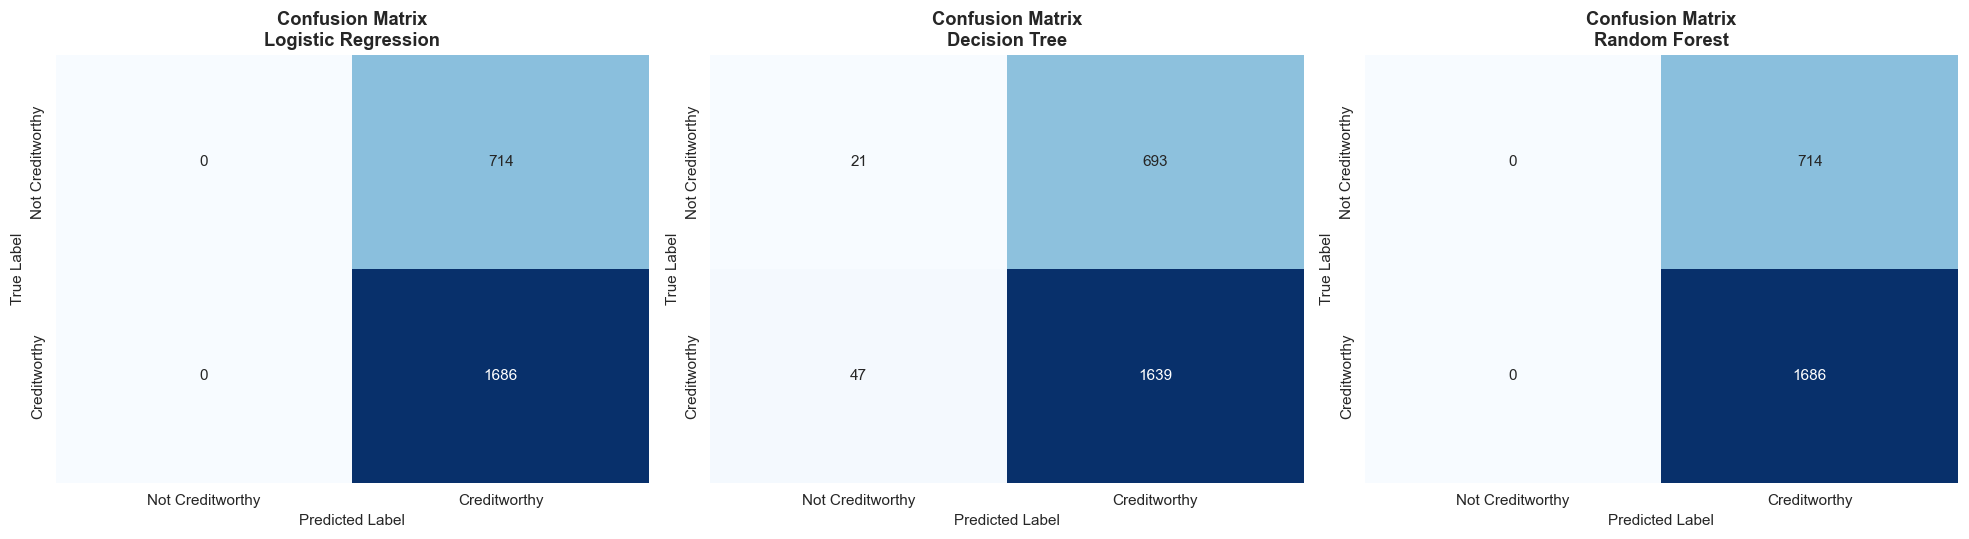


Plotting ROC-AUC curves...


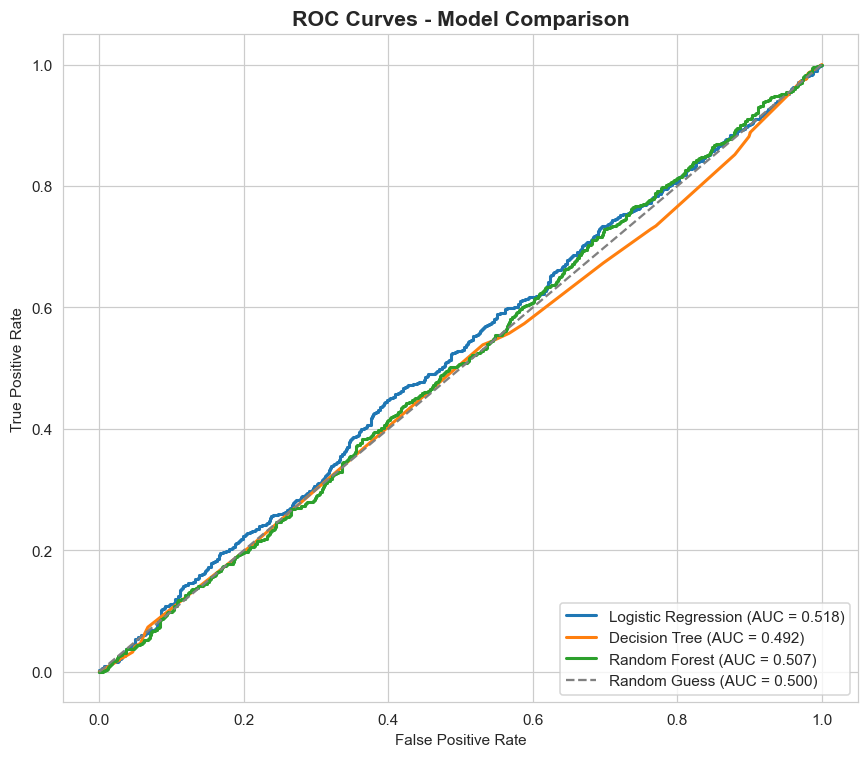


Plotting metric comparison bar chart...


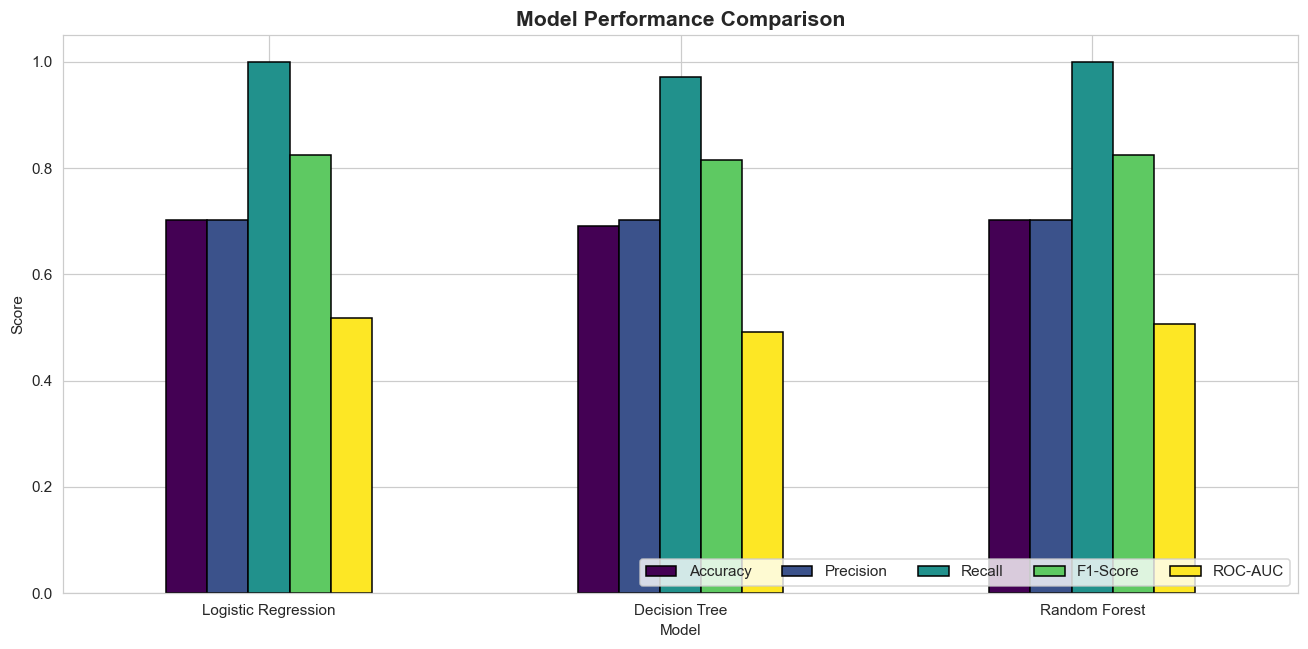


Plotting feature importance (Random Forest)...


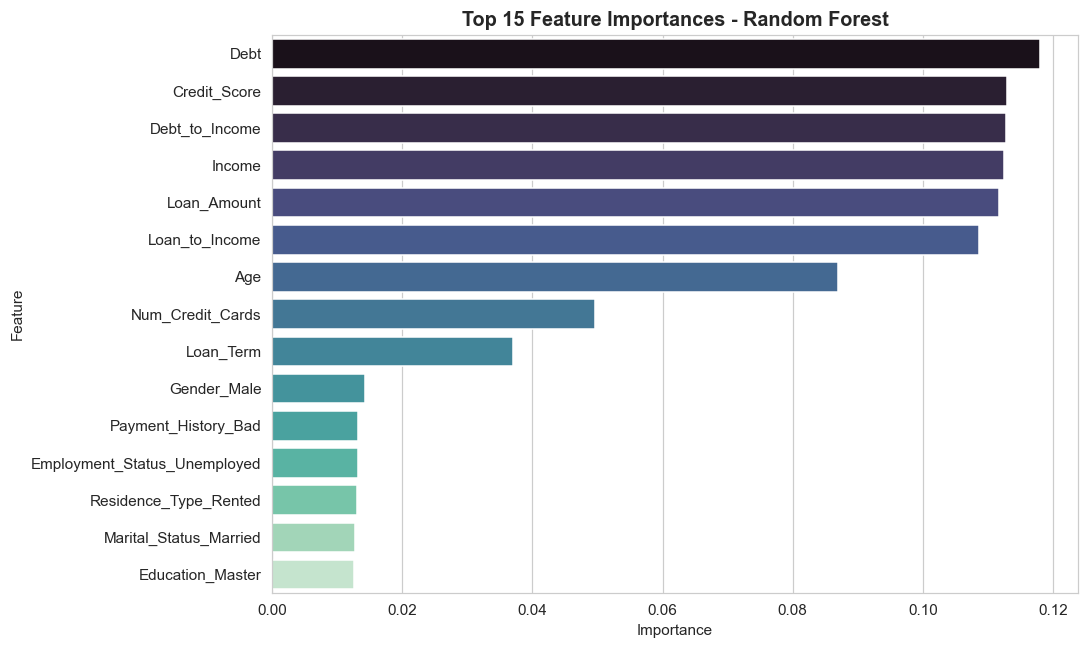


10. FINAL VERDICT
Best performing model based on ROC-AUC: Logistic Regression
                     Accuracy  Precision  Recall  F1-Score  ROC-AUC
Model                                                              
Logistic Regression    0.7025     0.7025     1.0    0.8253   0.5177

Done. Generated plots saved as:
 - confusion_matrices.png
 - roc_curves.png
 - model_comparison.png
 - feature_importance.png


In [1]:
"""
==============================================================================
 TASK 1: CREDIT SCORING MODEL
==============================================================================
Objective : Predict an individual's creditworthiness using past financial data.
Approach  : Classification algorithms - Logistic Regression, Decision Tree,
            Random Forest.
Key steps :
    1. Load & explore the dataset
    2. Feature engineering (encoding categoricals, scaling numerics)
    3. Train/test split
    4. Train 3 models: Logistic Regression, Decision Tree, Random Forest
    5. Evaluate with Accuracy, Precision, Recall, F1-score, ROC-AUC
    6. Print classification reports
    7. Plot confusion matrices (seaborn heatmaps)
    8. Plot ROC-AUC curves (all 3 models on one chart)
    9. Compare all models in a summary table + bar chart

Dataset columns:
    Age, Gender, Education, Income, Debt, Credit_Score, Loan_Amount,
    Loan_Term, Num_Credit_Cards, Payment_History, Employment_Status,
    Residence_Type, Marital_Status, Creditworthiness (TARGET: 0 = not
    creditworthy, 1 = creditworthy)
==============================================================================
"""

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, roc_auc_score
)

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Plot style
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

DATA_PATH = "creditscoring.csv"   # <-- change path if needed


# ==============================================================================
# 1. LOAD DATA
# ==============================================================================
print("=" * 80)
print("1. LOADING DATA")
print("=" * 80)

df = pd.read_csv(DATA_PATH)

print(f"Dataset shape : {df.shape}")
print("\nFirst 5 rows:")
print(df.head())

print("\nColumn data types:")
print(df.dtypes)

print("\nMissing values per column:")
print(df.isnull().sum())

print("\nTarget distribution (Creditworthiness):")
print(df["Creditworthiness"].value_counts())
print(df["Creditworthiness"].value_counts(normalize=True).round(3) * 100, "%")


# ==============================================================================
# 2. FEATURE ENGINEERING
# ==============================================================================
print("\n" + "=" * 80)
print("2. FEATURE ENGINEERING")
print("=" * 80)

target_col = "Creditworthiness"

# Identify categorical and numerical columns (excluding target)
categorical_cols = df.select_dtypes(include=["object", "string"]).columns.tolist()
numerical_cols = [c for c in df.columns if c not in categorical_cols + [target_col]]

print(f"Categorical columns : {categorical_cols}")
print(f"Numerical columns   : {numerical_cols}")

# Engineered features that often matter for credit scoring:
#   - Debt-to-Income ratio
#   - Loan-to-Income ratio
df["Debt_to_Income"] = df["Debt"] / (df["Income"] + 1)
df["Loan_to_Income"] = df["Loan_Amount"] / (df["Income"] + 1)
numerical_cols += ["Debt_to_Income", "Loan_to_Income"]

print("\nEngineered features added: Debt_to_Income, Loan_to_Income")

# One-Hot Encode categorical (nominal) features
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

print(f"\nShape after one-hot encoding: {df_encoded.shape}")

# Final feature matrix and target
X = df_encoded.drop(columns=[target_col])
y = df_encoded[target_col]

feature_names = X.columns.tolist()
print(f"\nTotal number of features used for modeling: {len(feature_names)}")


# ==============================================================================
# 3. TRAIN / TEST SPLIT + SCALING
# ==============================================================================
print("\n" + "=" * 80)
print("3. TRAIN/TEST SPLIT")
print("=" * 80)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Training set size : {X_train.shape[0]} rows")
print(f"Test set size      : {X_test.shape[0]} rows")

# Scale numerical features (important for Logistic Regression;
# tree-based models are scale-invariant but scaling doesn't hurt them)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test_scaled[numerical_cols] = scaler.transform(X_test[numerical_cols])


# ==============================================================================
# 4. TRAIN MODELS
# ==============================================================================
print("\n" + "=" * 80)
print("4. TRAINING MODELS")
print("=" * 80)

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=8, random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, random_state=RANDOM_STATE, n_jobs=-1
    ),
}

# Logistic Regression uses scaled data; trees can use either,
# we'll use scaled data consistently for all models for a fair pipeline.
trained_models = {}
predictions = {}
probabilities = {}

for name, model in models.items():
    print(f"\nTraining {name} ...")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    predictions[name] = model.predict(X_test_scaled)
    probabilities[name] = model.predict_proba(X_test_scaled)[:, 1]
    print(f"{name} training complete.")


# ==============================================================================
# 5. EVALUATION METRICS
# ==============================================================================
print("\n" + "=" * 80)
print("5. MODEL EVALUATION")
print("=" * 80)

results = []

for name in models.keys():
    y_pred = predictions[name]
    y_proba = probabilities[name]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)

    results.append({
        "Model": name,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-Score": f1,
        "ROC-AUC": auc
    })

    print("\n" + "-" * 80)
    print(f"MODEL: {name}")
    print("-" * 80)
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"ROC-AUC   : {auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=["Not Creditworthy", "Creditworthy"]))

# Summary comparison table
results_df = pd.DataFrame(results).set_index("Model").round(4)
print("\n" + "=" * 80)
print("MODEL COMPARISON SUMMARY")
print("=" * 80)
print(results_df)


# ==============================================================================
# 6. CONFUSION MATRICES (Seaborn heatmaps)
# ==============================================================================
print("\nPlotting confusion matrices...")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=["Not Creditworthy", "Creditworthy"],
        yticklabels=["Not Creditworthy", "Creditworthy"]
    )
    ax.set_title(f"Confusion Matrix\n{name}", fontsize=12, fontweight="bold")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")

plt.tight_layout()
plt.savefig("confusion_matrices.png", bbox_inches="tight")
plt.show()


# ==============================================================================
# 7. ROC-AUC CURVES
# ==============================================================================
print("\nPlotting ROC-AUC curves...")

plt.figure(figsize=(8, 7))

colors = ["#1f77b4", "#ff7f0e", "#2ca02c"]

for (name, y_proba), color in zip(probabilities.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_score:.3f})", color=color, linewidth=2)

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Random Guess (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Model Comparison", fontsize=14, fontweight="bold")
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig("roc_curves.png", bbox_inches="tight")
plt.show()


# ==============================================================================
# 8. METRIC COMPARISON BAR CHART
# ==============================================================================
print("\nPlotting metric comparison bar chart...")

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
plot_df = results_df[metrics_to_plot]

ax = plot_df.plot(kind="bar", figsize=(12, 6), colormap="viridis", edgecolor="black")
plt.title("Model Performance Comparison", fontsize=14, fontweight="bold")
plt.ylabel("Score")
plt.xlabel("Model")
plt.xticks(rotation=0)
plt.ylim(0, 1.05)
plt.legend(loc="lower right", ncol=5)
plt.tight_layout()
plt.savefig("model_comparison.png", bbox_inches="tight")
plt.show()


# ==============================================================================
# 9. FEATURE IMPORTANCE (Random Forest) - bonus insight
# ==============================================================================
print("\nPlotting feature importance (Random Forest)...")

rf_model = trained_models["Random Forest"]
importances = pd.Series(rf_model.feature_importances_, index=feature_names)
importances = importances.sort_values(ascending=False).head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=importances.values, y=importances.index, palette="mako")
plt.title("Top 15 Feature Importances - Random Forest", fontsize=13, fontweight="bold")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig("feature_importance.png", bbox_inches="tight")
plt.show()


# ==============================================================================
# 10. FINAL VERDICT
# ==============================================================================
print("\n" + "=" * 80)
print("10. FINAL VERDICT")
print("=" * 80)

best_model_name = results_df["ROC-AUC"].idxmax()
print(f"Best performing model based on ROC-AUC: {best_model_name}")
print(results_df.loc[[best_model_name]])

print("\nDone. Generated plots saved as:")
print(" - confusion_matrices.png")
print(" - roc_curves.png")
print(" - model_comparison.png")
print(" - feature_importance.png")